# NGC 1068: sensitivity by energy band, before and after the FOV cut

Calculate the source flux required for **TS = 9 in each measured-energy band**
for a cutoff power law with a **400 keV cutoff**, before and after the
**60-degree boresight cut**.
Compare the resulting spectral-energy-flux thresholds with the supplied
published COSI continuum sensitivity curve.

The source position is that of NGC 1068. Both cases use a **24-month survey**,
obtained by multiplying the three-month orientation livetimes and background
counts by eight. The cut retains fewer survey intervals; its retained exposure
is not rescaled to equal the uncut exposure. Earth occultation is included in
the source response in both cases.

The spectrum is
\[
\frac{dN}{dE}=K\left(\frac{E}{200\;\mathrm{keV}}\right)^{-2.1}
\exp(-E/E_c),\qquad E_c=400\;\mathrm{keV}.
\]
Position, index, and cutoff are fixed. One source amplitude is tested, with one
background normalization profiled **separately within each band**.
TS = 9 denotes nominal, local, asymptotic 3-sigma sensitivity.

Run from top to bottom with the cosipy312 kernel. The notebook defines all its
own calculations and includes the 37 published CSV points below. It does not
load results or helper functions from another notebook. Outputs are displayed
inline and saved as **PDFs and CSVs only**.

## 1. Inputs and comparison conventions

The published reference is the continuum **requirement-level** curve in
[Tomsick et al., Figure 2b](https://arxiv.org/pdf/2308.12362), described there
as point-source, 3-sigma sensitivity in two years of survey observations.
The supplied CSV labels its axes as energy in MeV and
\(\nu F_\nu\) in erg cm\(^{-2}\) s\(^{-1}\).

We use **all ten native response bins from 100 to 10,000 keV (0.1-10 MeV)**.
No measured-energy bins are split or omitted. The published curve retains its
original 37 points and approximately 0.2-5 MeV range; it is not extended or
extrapolated. Published comparison values and ratios are left blank in the
CSVs wherever a simulated band center falls outside that reference range.

Each band uses only its measured-energy counts and its full Compton data space
(Phi and PsiChi). A complete CPL is folded over all true energies in the
response, so energy migration from adjacent true-energy bins is included.
The reported band flux integrates that same CPL between the measured band's
nominal edges. A diagnostic reports how much of the selected source expectation
comes from true energies inside those edges.

**Interpretation:** these are thresholds for the stated CPL and the DC4 data
at the NGC 1068 position. The published CSV does not specify its bandwidth or
reference spectrum. Its value at each band center is therefore a **benchmark**,
not an exactly matched sensitivity prediction. No bandwidth correction is
assumed. Changing the FOV cut also changes the time-integrated source/background
templates; this is not a time-resolved optimal analysis.

In [1]:
%%capture
from pathlib import Path
from io import StringIO
import time

import astropy.units as u
from astropy.coordinates import SkyCoord
from astromodels import Cutoff_powerlaw
import h5py
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.optimize import brentq

from cosipy import SpacecraftHistory
from cosipy.event_selection import GoodTimeInterval
from cosipy.response import FullDetectorResponse
from cosipy.response.functions import get_integrated_spectral_model

%matplotlib inline

In [2]:
NOTEBOOK_DIR = Path('/Users/parshadkp/Software/cosipy/docs/tutorials/source_injector')
DATA_DIR = Path(
    '/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/'
    'COSI/Radio_Quiet_AGN/DC4_Files'
)
RESPONSE_PATH = DATA_DIR / (
    'ResponseContinuum.o3.e100_10000.b10log.s10396905069491.'
    'm2284.filtered.nonsparse.binnedimaging.imagingresponse.h5'
)
ORIENTATION_PATH = DATA_DIR / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits'
BACKGROUND_PATHS = {
    'no_fov_cut': DATA_DIR / 'Background' / (
        'Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck.hdf5'
    ),
    'fov60': DATA_DIR / 'Background' / (
        'Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_'
        'NGC1068_60deg_fov_cut.hdf5'
    ),
}
SELECTION_LABELS = {'no_fov_cut': 'Before FOV cut', 'fov60': 'After 60-degree FOV cut'}
OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / 'NGC1068_band_sensitivity_FOV_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_MONTHS = 3.0
EXPOSURE_MONTHS = 24.0
EXPOSURE_MULTIPLIER = EXPOSURE_MONTHS / BASE_MONTHS
MAX_OFFAXIS = 60.0 * u.deg
SOURCE_COORD = SkyCoord(l=172.104, b=-51.934, unit='deg', frame='galactic')
INDEX = -2.1
PIVOT_KEV = 200.0
CUTOFFS_KEV = (400.0,)
REFERENCE_K = 1e-6  # ph cm^-2 s^-1 keV^-1; an arbitrary numerical reference.
ANALYSIS_RANGE_KEV = (100.0, 10000.0)
TARGET_TS = 9.0
PROFILE_BACKGROUND = True
KEV_TO_ERG = u.keV.to(u.erg)
STEM = f'NGC1068_24months_index_m2p1_native_bands_TS9'

for input_path in [RESPONSE_PATH, ORIENTATION_PATH, *BACKGROUND_PATHS.values()]:
    if not input_path.is_file():
        raise FileNotFoundError(input_path)
assert EXPOSURE_MULTIPLIER > 0

The following data are copied verbatim from the user-supplied
COSI_sensitivity_Tomsick2024.csv. Keeping them here makes the reference
independent of a Downloads-folder path. Interpolation is linear in log energy
and log spectral energy flux, without extrapolation.

In [3]:
PUBLISHED_CSV = """
E[MeV], nuFnu[erg/cm2/s]
0.20053746897999322, 3.5919034492936284e-11
0.2288152965636668, 3.446781280078777e-11
0.24970210529143802, 3.374615561296502e-11
0.27249848408712213, 3.2900083482598146e-11
0.2973749611667684, 3.212050192819525e-11
0.3245212402533514, 3.1403660551887075e-11
0.354141741849968, 3.083302320046783e-11
0.38643914375407323, 3.109509428510975e-11
0.4216820390764531, 3.1359392892267474e-11
0.460140727016999, 3.158135696583971e-11
0.5020887101142999, 3.225672021364143e-11
0.5478090280668025, 3.417731626769757e-11
0.5976796112715294, 3.652005942780669e-11
0.6520973471197494, 3.885859641824672e-11
0.7114697274279783, 4.1346880023049924e-11
0.7762450421920931, 4.405660283813126e-11
0.8469147057489167, 4.7010178077905835e-11
0.9240181641460025, 5.016176238181665e-11
1.0081301570216379, 5.3751620390138986e-11
1.0998707474415406, 5.8169955520343746e-11
1.1999597994881215, 6.295147384728051e-11
1.3091570293482193, 6.81260287049541e-11
1.4282860952008467, 7.383000060494989e-11
1.5582441912220892, 8.023759942974774e-11
1.7000455659011642, 8.683305835267185e-11
1.8547509706251721, 9.397065810125794e-11
2.023527324848953, 1.0183851717689943e-10
2.207637704115712, 1.1083316876506867e-10
2.408508099546709, 1.204522189629377e-10
2.627645906202078, 1.3109088272815654e-10
2.8667323610345146, 1.424680705817129e-10
3.1275616445163936, 1.550512335424938e-10
3.4121348528365836, 1.685079055415427e-10
3.7225875134706357, 1.8339097672339798e-10
4.061330966771419, 1.987457096768392e-10
4.430834545271774, 2.1660479843499172e-10
4.995320017505503, 2.4444187330378066e-10
"""

published = pd.read_csv(StringIO(PUBLISHED_CSV), skipinitialspace=True)
published.columns = ['energy_MeV', 'nufnu_erg_cm2_s']
published = published.sort_values('energy_MeV').reset_index(drop=True)
assert len(published) == 37
assert np.all(np.isfinite(published.to_numpy()))
assert np.all(published.to_numpy() > 0)
assert np.all(np.diff(published['energy_MeV']) > 0)

def published_at(energy_MeV):
    energy = np.asarray(energy_MeV, dtype=float)
    x = published['energy_MeV'].to_numpy()
    y = published['nufnu_erg_cm2_s'].to_numpy()
    inside = (energy >= x[0]) & (energy <= x[-1])
    return np.where(inside, np.exp(np.interp(np.log(energy), np.log(x), np.log(y))), np.nan)

print(f'Published reference: {len(published)} points, '
      f'{published.energy_MeV.min():.4f}-{published.energy_MeV.max():.4f} MeV.')

Published reference: 37 points, 0.2005-4.9953 MeV.


## 2. Read matched backgrounds and construct the two exposure selections

The uncut background retains the existing SAA selections; "before the cut"
means before the additional source-boresight FOV selection. The second file
was selected using the NGC 1068 60-degree GTI. These are actual matching
background selections, rather than one background scaled by a livetime ratio.

The files contain large sparse time histograms. Reading and projecting them
in chunks avoids loading their full time-coordinate arrays into memory.
This sums the Time axis exactly; it does not smooth, rebin, or approximate
the counts. Background expectations are then multiplied by eight.
Empty leading time bins may extend before the orientation begins. The timing
check uses occupied bins and therefore checks overlap at the background's
native time-bin resolution, not event-level boundary precision.
For the supplied DC4 files, a separate check of the backing unbinned background
confirmed that its earliest and latest events both lie inside this orientation
history. The earlier histogram edges are padding, not extra exposure.

In [4]:
def read_projected_background(path, chunk_size=1_000_000):
    with h5py.File(path, 'r') as handle:
        hist = handle['hist']
        if hist.attrs['format'] != 'coo':
            raise ValueError('This reader expects a sparse COO histogram.')
        axes = list(hist['axes'].values())
        labels = [axis.attrs['label'] for axis in axes]
        if labels != ['Time', 'Em', 'Phi', 'PsiChi']:
            raise ValueError(f'Unexpected background axes: {labels}')
        if float(hist['contents/fill_value'][()]) != 0:
            raise ValueError('A nonzero sparse fill value needs a different projection.')
        shape = tuple(int(n) for n in hist['contents/shape'][()][1:])
        projected = np.zeros(np.prod(shape), dtype=float)
        coordinates = hist['contents/coords']
        values = hist['contents/data']
        input_sum = 0.0
        first_occupied, last_occupied = len(axes[0]) - 1, -1
        for start in range(0, len(values), chunk_size):
            stop = min(start + chunk_size, len(values))
            all_indices = np.asarray(coordinates[:, start:stop], dtype=np.int64)
            indices = all_indices[1:]
            weights = np.asarray(values[start:stop], dtype=float)
            if np.any(weights < 0) or not np.all(np.isfinite(weights)):
                raise ValueError('Invalid background counts.')
            flattened = np.ravel_multi_index(indices, shape)
            projected += np.bincount(flattened, weights=weights, minlength=projected.size)
            input_sum += float(weights.sum())
            occupied_times = all_indices[0, weights > 0]
            if occupied_times.size:
                first_occupied = min(first_occupied, int(occupied_times.min()))
                last_occupied = max(last_occupied, int(occupied_times.max()))
        np.testing.assert_allclose(projected.sum(), input_sum, rtol=1e-12)
        metadata = {
            'energy_edges_keV': np.asarray(axes[1][()], dtype=float),
            'phi_edges_deg': np.asarray(axes[2][()], dtype=float),
            'psichi_edges': np.asarray(axes[3][()]),
            'psichi_nside': int(axes[3].attrs['nside']),
            'psichi_scheme': str(axes[3].attrs['scheme']),
            'psichi_coordsys': str(axes[3].attrs['coordsys']),
            'time_range_s': (float(axes[0][0]), float(axes[0][-1])),
            'first_occupied_time_bin_s': (float(axes[0][first_occupied]), float(axes[0][first_occupied + 1])),
            'last_occupied_time_bin_s': (float(axes[0][last_occupied]), float(axes[0][last_occupied + 1])),
        }
    return projected.reshape(shape) * EXPOSURE_MULTIPLIER, metadata

backgrounds, background_metadata = {}, {}
for selection, input_path in BACKGROUND_PATHS.items():
    backgrounds[selection], background_metadata[selection] = read_projected_background(input_path)
    print(f'{SELECTION_LABELS[selection]}: {backgrounds[selection].sum():,.0f} background counts '
          f'over the full response energy range.')

for key in ('energy_edges_keV', 'phi_edges_deg', 'psichi_edges'):
    np.testing.assert_array_equal(background_metadata['no_fov_cut'][key],
                                  background_metadata['fov60'][key])
for key in ('psichi_nside', 'psichi_scheme', 'psichi_coordsys'):
    assert background_metadata['no_fov_cut'][key] == background_metadata['fov60'][key]
assert np.all(backgrounds['fov60'] <= backgrounds['no_fov_cut'] + 1e-7)

full_orientation = SpacecraftHistory.open(ORIENTATION_PATH)
source_gti = GoodTimeInterval.from_pointing_cut(
    SOURCE_COORD, full_orientation, MAX_OFFAXIS, earth_occ=False,
)
orientations_3m = {
    'no_fov_cut': full_orientation,
    'fov60': full_orientation.apply_gti(source_gti),
}
orientations, exposure_rows = {}, []
for selection, orientation_3m in orientations_3m.items():
    scaled = SpacecraftHistory(
        orientation_3m.obstime, orientation_3m.attitude, orientation_3m.location,
        livetime=orientation_3m.livetime * EXPOSURE_MULTIPLIER,
    )
    scaled.cache_earth_occ = orientation_3m.cache_earth_occ
    orientations[selection] = scaled
    livetime_3m = float(orientation_3m.cumulative_livetime().to_value(u.s))
    livetime_24m = float(scaled.cumulative_livetime().to_value(u.s))
    np.testing.assert_allclose(livetime_24m, livetime_3m * EXPOSURE_MULTIPLIER)
    first_bin = background_metadata[selection]['first_occupied_time_bin_s']
    last_bin = background_metadata[selection]['last_occupied_time_bin_s']
    assert first_bin[1] > full_orientation.obstime.unix[0]
    assert last_bin[0] < full_orientation.obstime.unix[-1]
    assert first_bin[0] >= full_orientation.obstime.unix[0] - (first_bin[1] - first_bin[0]) - 1
    assert last_bin[1] <= full_orientation.obstime.unix[-1] + (last_bin[1] - last_bin[0]) + 1
    exposure_rows.append({
        'selection': SELECTION_LABELS[selection],
        'livetime_3months_s': livetime_3m,
        'livetime_24months_s': livetime_24m,
        'background_counts_100_10000keV': backgrounds[selection].sum(),
    })
exposure_summary = pd.DataFrame(exposure_rows)
exposure_summary['retained_livetime_fraction'] = (
    exposure_summary['livetime_24months_s'] / exposure_summary.loc[0, 'livetime_24months_s']
)
display(exposure_summary)

Before FOV cut: 1,349,188,352 background counts over the full response energy range.
After 60-degree FOV cut: 507,151,368 background counts over the full response energy range.


,selection,livetime_3months_s,livetime_24months_s,background_counts_100_10000keV,retained_livetime_fraction
0,Before FOV cut,6579555.0,52636440.0,1.349188e+09,1.000000
1,After 60-degree FOV cut,2546115.0,20368920.0,5.071514e+08,0.386974


## 3. Fold each exposure once and form the spectral templates

The response is convolved with the orientation using the same attitude-map
method as SourceInjector, including Earth occultation. Its livetime scaling
already supplies the factor of eight to the source expectation. The response
file is not multiplied by an additional factor of eight.

The spectrum reuses the response for each exposure selection. Source and
background axes are checked before forming any likelihood.

In [5]:
energy_edges = background_metadata['no_fov_cut']['energy_edges_keV']
band_indices = np.flatnonzero(
    (energy_edges[:-1] >= ANALYSIS_RANGE_KEV[0]) &
    (energy_edges[1:] <= ANALYSIS_RANGE_KEV[1])
)
if not len(band_indices):
    raise ValueError('No whole response energy bins lie in the comparison range.')
bands = pd.DataFrame({
    'response_bin': band_indices,
    'energy_min_keV': energy_edges[band_indices],
    'energy_max_keV': energy_edges[band_indices + 1],
})
bands['energy_center_MeV'] = np.sqrt(bands.energy_min_keV * bands.energy_max_keV) / 1000
bands['delta_E_over_Ecenter'] = (
    (bands.energy_max_keV - bands.energy_min_keV) / (1000 * bands.energy_center_MeV)
)
display(bands.drop(columns='response_bin'))

def make_spectrum(cutoff_keV):
    spectrum = Cutoff_powerlaw()
    spectrum.K.value = REFERENCE_K
    spectrum.K.unit = u.keV**-1 * u.cm**-2 * u.s**-1
    spectrum.piv.value = PIVOT_KEV
    spectrum.piv.unit = u.keV
    spectrum.index.value = INDEX
    spectrum.xc.value = cutoff_keV
    spectrum.xc.unit = u.keV
    for parameter in spectrum.parameters.values():
        parameter.fix = True
    return spectrum

def dense_values(histogram):
    contents = histogram.contents
    if hasattr(contents, 'compute'):
        contents = contents.compute()
    if hasattr(contents, 'todense'):
        contents = contents.todense()
    if hasattr(contents, 'value'):
        contents = contents.value
    return np.asarray(contents, dtype=float)

spectra = {cutoff: make_spectrum(cutoff) for cutoff in CUTOFFS_KEV}
source_templates, same_true_band_templates = {}, {}
response_start = time.perf_counter()
with FullDetectorResponse.open(RESPONSE_PATH) as detector_response:
    for selection, orientation in orientations.items():
        start = time.perf_counter()
        attitude_map = orientation.get_scatt_map(
            detector_response.nside * 2, target_coord=SOURCE_COORD, earth_occ=True,
        )
        psr = detector_response.get_point_source_response(coord=SOURCE_COORD, scatt_map=attitude_map)
        for cutoff, spectrum in spectra.items():
            expectation = psr.get_expectation(spectrum).project('Em', 'Phi', 'PsiChi')
            metadata = background_metadata[selection]
            np.testing.assert_allclose(expectation.axes['Em'].edges.to_value(u.keV),
                                       metadata['energy_edges_keV'], rtol=1e-10)
            np.testing.assert_allclose(expectation.axes['Phi'].edges.to_value(u.deg),
                                       metadata['phi_edges_deg'], rtol=1e-10, atol=1e-10)
            np.testing.assert_array_equal(expectation.axes['PsiChi'].edges,
                                          metadata['psichi_edges'])
            assert expectation.axes['PsiChi'].nside == metadata['psichi_nside']
            assert expectation.axes['PsiChi'].scheme == metadata['psichi_scheme']
            assert expectation.axes['PsiChi'].coordsys.name == metadata['psichi_coordsys']
            values = dense_values(expectation)
            assert values.shape == backgrounds[selection].shape
            assert np.all(np.isfinite(values)) and np.all(values >= 0)
            source_templates[selection, cutoff] = values

            # Diagnose migration: keep only incident true-energy bins inside each band.
            incident_flux = get_integrated_spectral_model(spectrum, psr.axes['Ei'])
            true_edges = psr.axes['Ei'].edges.to_value(u.keV)
            for band in bands.itertuples():
                np.testing.assert_allclose(true_edges[band.response_bin:band.response_bin + 2],
                                           [band.energy_min_keV, band.energy_max_keV], rtol=1e-5)
                inside = np.zeros(len(true_edges) - 1, dtype=bool)
                inside[band.response_bin] = True
                band_incident_flux = incident_flux.copy()
                band_incident_flux[:] = dense_values(incident_flux) * inside * incident_flux.unit
                band_expectation = psr.get_expectation(spectrum, flux=band_incident_flux)
                same_true_band_templates[selection, cutoff, band.response_bin] = (
                    dense_values(band_expectation)[band.response_bin]
                )
        print(f'{SELECTION_LABELS[selection]} response: {time.perf_counter() - start:.1f} s.')
        del psr
print(f'Total response preparation: {time.perf_counter() - response_start:.1f} s.')

Before FOV cut response: 11.7 s.
After 60-degree FOV cut response: 6.8 s.
Total response preparation: 18.5 s.


,energy_min_keV,energy_max_keV,energy_center_MeV,delta_E_over_Ecenter
0,100.000,158.489,0.125892,0.464595
1,158.489,251.189,0.199526,0.464601
2,251.189,398.107,0.316228,0.464595
3,398.107,630.957,0.501187,0.464597
4,630.957,1000.000,0.794328,0.464598
5,1000.000,1584.890,1.258924,0.464595
6,1584.890,2511.890,1.995262,0.464601
7,2511.890,3981.070,3.162279,0.464595
8,3981.070,6309.570,5.011870,0.464597
9,6309.570,10000.000,7.943280,0.464598


## 4. Solve the Asimov likelihood for TS = 9 in each band

In a selected band, retain cells with \(b_i>0\), applying the same mask to the
source. Let \(p_i=s_i/\sum s_i\) be its normalized source template and let
\(N_s\) be the expected retained source counts. For Asimov data
\(n_i=b_i+N_sp_i\), the source-plus-background model fits the expectation exactly.
The background-only best fit is \(\hat\beta_0=1+N_s/B\), where \(B=\sum b_i\).

Using \(h(r)=(1+r)\ln(1+r)-r\), the exact Asimov statistic is
\[
\mathrm{TS}_A(N_s)=2\left[\sum_i b_i h(N_sp_i/b_i)-B h(N_s/B)\right].
\]
Root finding gives \(N_s\) at TS = 9 directly, without a flux-grid interpolation.
Its source amplitude gives the integrated energy flux, photon flux, and
\(\nu F_\nu(E_0)=E_0^2\,dN/dE(E_0)\), with \(E_0=\sqrt{E_1E_2}\).
The keV-to-erg conversion is included explicitly.

These are **independent band thresholds**. Each row corresponds to a separately
normalized source, not one spectrum that reaches TS = 9 in every band at once.
The source template assumes the full CPL outside the selected energy band;
the migration diagnostic below matters particularly far above its cutoff.

In [6]:
def deviance_kernel(ratio):
    ratio = np.asarray(ratio, dtype=float)
    small = ratio < 1e-4
    result = np.empty_like(ratio)
    r = ratio[small]
    result[small] = r*r*(0.5 + r*(-1/6 + r*(1/12 + r*(-1/20 + r/30))))
    r = ratio[~small]
    result[~small] = (1+r)*np.log1p(r)-r
    return result

def asimov_ts(source_counts, source_probability, background):
    total_background = float(background.sum())
    ts = 2 * np.sum(background * deviance_kernel(source_counts * source_probability / background))
    if PROFILE_BACKGROUND:
        ts -= 2 * total_background * deviance_kernel(np.asarray(source_counts / total_background))
    if ts < -1e-8:
        raise ArithmeticError(f'Unexpected negative TS: {ts}')
    return max(0.0, float(ts))

def threshold_amplitude(source, background):
    source, background = np.ravel(source), np.ravel(background)
    support = background > 0
    s, b = source[support], background[support]
    if not s.sum() > 0:
        raise ValueError('No supported source counts in this band.')
    p = s / s.sum()
    information = float(np.sum(p*p / b))
    if PROFILE_BACKGROUND:
        information -= 1 / b.sum()
    if information <= 1e-12 * np.sum(p*p / b):
        raise ValueError('Source and background cannot be distinguished in this band.')
    upper = max(1.0, 2 * np.sqrt(TARGET_TS / information))
    while asimov_ts(upper, p, b) < TARGET_TS:
        upper *= 2
    counts = brentq(lambda n: asimov_ts(n, p, b) - TARGET_TS,
                    0.0, upper, xtol=1e-8, rtol=1e-12)
    actual_ts = asimov_ts(counts, p, b)
    np.testing.assert_allclose(actual_ts, TARGET_TS, rtol=1e-7, atol=1e-7)
    return counts / s.sum(), counts, actual_ts, support

# Check the stable statistic against a direct Poisson likelihood calculation.
toy_background = np.array([120.0, 200.0, 80.0])
toy_source = np.array([30.0, 5.0, 20.0])
toy_n = toy_background + toy_source
toy_null = toy_background * (toy_n.sum()/toy_background.sum() if PROFILE_BACKGROUND else 1)
toy_direct = 2 * np.sum(toy_n * np.log(toy_n/toy_null) + toy_null - toy_n)
np.testing.assert_allclose(asimov_ts(toy_source.sum(), toy_source/toy_source.sum(), toy_background),
                           toy_direct, rtol=1e-12)

result_rows, diagnostic_rows = [], []
for selection in SELECTION_LABELS:
    for cutoff in CUTOFFS_KEV:
        def shape(energy_keV):
            return (energy_keV/PIVOT_KEV)**INDEX * np.exp(-energy_keV/cutoff)
        for band in bands.itertuples():
            source = source_templates[selection, cutoff][band.response_bin].ravel()
            background = backgrounds[selection][band.response_bin].ravel()
            amplitude, counts, ts, support = threshold_amplitude(source, background)
            threshold_k = REFERENCE_K * amplitude
            energy_per_k = KEV_TO_ERG * quad(
                lambda e: e*shape(e), band.energy_min_keV, band.energy_max_keV,
                epsabs=0, epsrel=1e-10,
            )[0]
            photon_per_k = quad(shape, band.energy_min_keV, band.energy_max_keV,
                                  epsabs=0, epsrel=1e-10)[0]
            center_keV = 1000 * band.energy_center_MeV
            sed = KEV_TO_ERG * threshold_k * center_keV**2 * shape(center_keV)
            paper_sed = float(published_at(band.energy_center_MeV))
            result_rows.append({
                'selection': selection, 'cutoff_keV': cutoff,
                'energy_min_keV': band.energy_min_keV,
                'energy_max_keV': band.energy_max_keV,
                'energy_center_MeV': band.energy_center_MeV,
                'ts': ts,
                'energy_flux_erg_cm2_s': threshold_k * energy_per_k,
                'photon_flux_ph_cm2_s': threshold_k * photon_per_k,
                'nufnu_erg_cm2_s': sed,
                'band_mean_nufnu_erg_cm2_s': threshold_k * energy_per_k / np.log(
                    band.energy_max_keV / band.energy_min_keV),
                'published_nufnu_erg_cm2_s': paper_sed,
                'nufnu_over_published_benchmark': sed / paper_sed,
            })
            same_band = same_true_band_templates[selection, cutoff, band.response_bin]
            retained = float(source[support].sum() / source.sum())
            same_true_fraction = float(same_band.ravel()[support].sum() / source[support].sum())
            diagnostic_rows.append({
                'selection': selection, 'cutoff_keV': cutoff,
                'energy_min_keV': band.energy_min_keV, 'energy_max_keV': band.energy_max_keV,
                'positive_background_cells': int(support.sum()),
                'total_cells': source.size,
                'retained_source_fraction': retained,
                'source_counts_at_TS9': counts,
                'background_counts': float(background.sum()),
                'same_true_energy_band_fraction': same_true_fraction,
                'source_counts_at_band_flux_1e_m10': float(
                    source[support].sum() * 1e-10 / (REFERENCE_K * energy_per_k)
                ),
            })
results = pd.DataFrame(result_rows)
diagnostics = pd.DataFrame(diagnostic_rows)
benchmark_columns = ['published_nufnu_erg_cm2_s', 'nufnu_over_published_benchmark']
simulated_columns = [column for column in results.select_dtypes('number').columns
                     if column not in benchmark_columns]
assert np.all(np.isfinite(results[simulated_columns]))
within_published = results.energy_center_MeV.between(
    published.energy_MeV.min(), published.energy_MeV.max())
assert np.all(np.isfinite(results.loc[within_published, benchmark_columns]))
assert results.loc[~within_published, benchmark_columns].isna().all().all()
assert np.all(results['energy_flux_erg_cm2_s'] > 0)
assert np.all((diagnostics.retained_source_fraction > 0) & (diagnostics.retained_source_fraction <= 1+1e-10))
assert np.all((diagnostics.same_true_energy_band_fraction >= 0) &
              (diagnostics.same_true_energy_band_fraction <= 1+1e-10))
print(f'{len(results)} band/selection/spectrum thresholds verified at TS = {TARGET_TS:g}.')

20 band/selection/spectrum thresholds verified at TS = 9.


## 5. Values before and after the cut

The threshold ratio is **after / before**. A value below one means the cut
reduces the flux needed for detection; a value above one means the cut worsens
the threshold. The same ratio applies to integrated band energy flux and
\(\nu F_\nu\) for a fixed spectral shape.

The ratios to the published curve are pointwise benchmark ratios at the
geometric band centers. They do not account for an unknown published bandwidth,
reference spectrum, or differences between the requirement-level instrument
model and the DC4 response/background.

Published benchmark values and ratios are unavailable outside the digitized
curve's energy range. They are saved as blank CSV fields, without extrapolation.

In [7]:
join_keys = ['cutoff_keV', 'energy_min_keV', 'energy_max_keV', 'energy_center_MeV']
value_columns = ['energy_flux_erg_cm2_s', 'nufnu_erg_cm2_s', 'nufnu_over_published_benchmark']
comparison = (
    results.loc[results.selection == 'no_fov_cut', join_keys + value_columns]
    .merge(results.loc[results.selection == 'fov60', join_keys + value_columns],
           on=join_keys, suffixes=('_before', '_after'), validate='one_to_one')
)
comparison['threshold_ratio_after_over_before'] = (
    comparison.energy_flux_erg_cm2_s_after / comparison.energy_flux_erg_cm2_s_before
)
comparison['threshold_change_percent'] = 100 * (comparison.threshold_ratio_after_over_before - 1)

for cutoff in CUTOFFS_KEV:
    subset = comparison.loc[comparison.cutoff_keV == cutoff]
    print(f'Cutoff = {cutoff:g} keV; band energy flux in erg cm^-2 s^-1')
    table = pd.DataFrame({
        'Band (keV)': [f'{lo:.1f}-{hi:.1f}' for lo, hi in zip(subset.energy_min_keV, subset.energy_max_keV)],
        'Before FOV cut': subset.energy_flux_erg_cm2_s_before,
        'After 60-degree cut': subset.energy_flux_erg_cm2_s_after,
        'After / before': subset.threshold_ratio_after_over_before,
        'Change (%)': subset.threshold_change_percent,
    })
    display(table.style.hide(axis='index').format({
        'Before FOV cut': '{:.3e}', 'After 60-degree cut': '{:.3e}',
        'After / before': '{:.3f}', 'Change (%)': '{:+.1f}',
    }))

results_csv = OUTPUT_DIR / f'{STEM}_sensitivity_by_band.csv'
comparison_csv = OUTPUT_DIR / f'{STEM}_before_after_FOV.csv'
results.to_csv(results_csv, index=False, float_format='%.12g')
comparison.to_csv(comparison_csv, index=False, float_format='%.12g')
print('Saved:', results_csv)
print('Saved:', comparison_csv)

Cutoff = 400 keV; band energy flux in erg cm^-2 s^-1
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_band_sensitivity_FOV_comparison/NGC1068_24months_index_m2p1_native_bands_TS9_sensitivity_by_band.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_band_sensitivity_FOV_comparison/NGC1068_24months_index_m2p1_native_bands_TS9_before_after_FOV.csv


Band (keV),Before FOV cut,After 60-degree cut,After / before,Change (%)
100.0-158.5,3.883e-11,3.077e-11,0.792,-20.8
158.5-251.2,1.712e-11,1.380e-11,0.806,-19.4
251.2-398.1,1.575e-11,1.247e-11,0.792,-20.8
398.1-631.0,1.886e-11,1.397e-11,0.741,-25.9
631.0-1000.0,2.665e-11,1.935e-11,0.726,-27.4
1000.0-1584.9,4.219e-11,3.104e-11,0.736,-26.4
1584.9-2511.9,7.078e-11,5.341e-11,0.755,-24.5
2511.9-3981.1,1.611e-10,1.298e-10,0.806,-19.4
3981.1-6309.6,5.292e-10,4.701e-10,0.888,-11.2
6309.6-10000.0,2.363e-09,2.155e-09,0.912,-8.8


## 6. Compare spectral-energy-flux sensitivity with the published curve

Horizontal bars show the actual simulated energy windows. All curves refer to
the same 24-month survey duration. The black curve is the published benchmark;
the two colored curves in each panel are independent band TS = 9 thresholds.
A spectral energy flux at the geometric band center differs from the mean
over the band. The next section compares these two conventions.

Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_band_sensitivity_FOV_comparison/NGC1068_24months_index_m2p1_native_bands_TS9_published_comparison.pdf


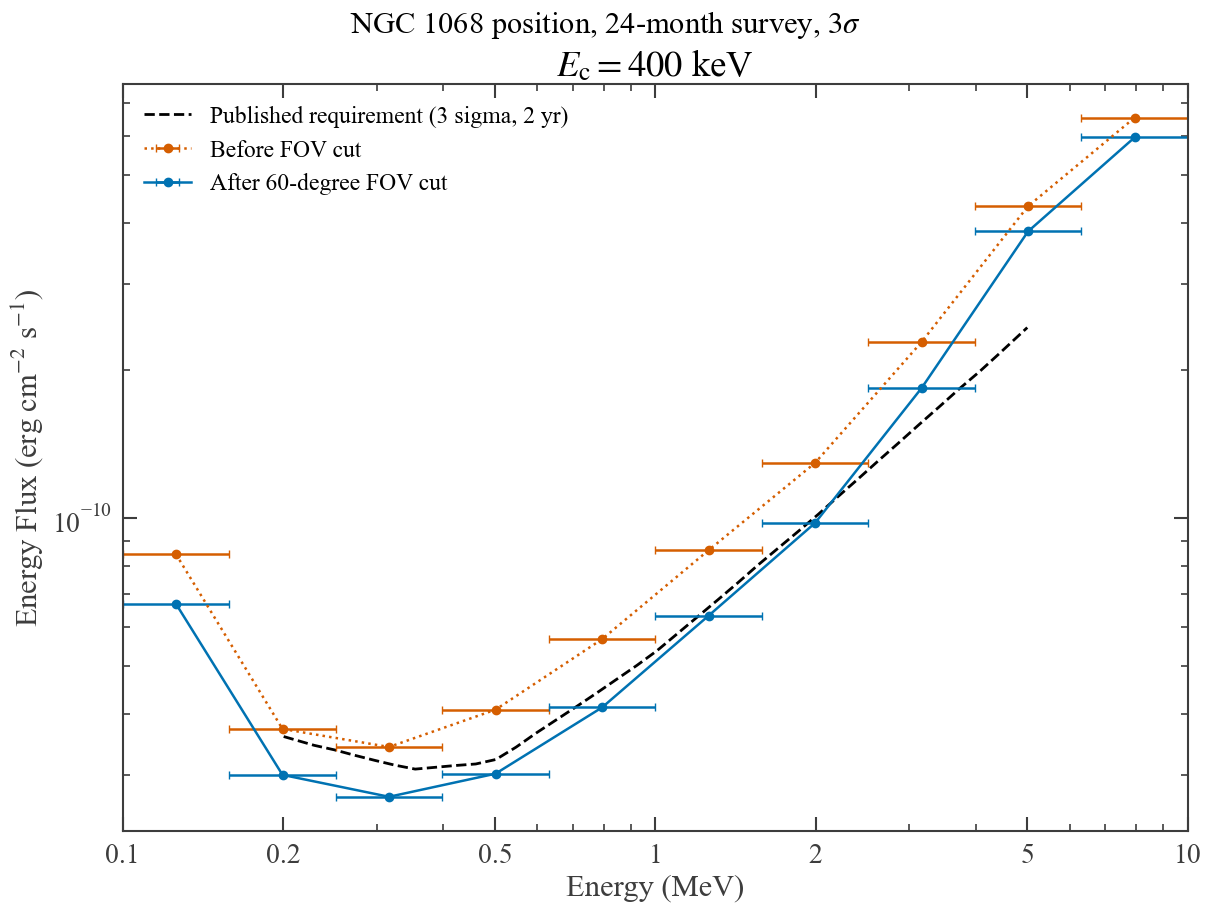

In [8]:
PLOT_STYLE = {
    'font.family': 'Times New Roman', 'font.size': 22, 'font.weight': 'normal',
    'mathtext.fontset': 'stix',
    'axes.labelweight': 'normal', 'axes.titleweight': 'normal',
    'axes.linewidth': 1.5, 'axes.labelsize': 22, 'legend.fontsize': 17,
    'xtick.labelsize': 20, 'ytick.labelsize': 20,
}
COLORS = {'no_fov_cut': '#D55E00', 'fov60': '#0072B2'}

def style_axes(ax):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(FixedLocator([0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'))
    ax.tick_params(which='both', direction='in', top=True, right=True, pad=8)
    ax.tick_params(which='major', length=10, width=1.5)
    ax.tick_params(which='minor', length=5, width=1.2)

with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(CUTOFFS_KEV), figsize=(12, 9),
                             sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, cutoff in zip(axes, CUTOFFS_KEV):
        ax.plot(published.energy_MeV, published.nufnu_erg_cm2_s,
                color='black', linestyle='--', linewidth=2,
                label='Published requirement (3 sigma, 2 yr)')
        for selection in SELECTION_LABELS:
            subset = results.loc[(results.selection == selection) &
                                 (results.cutoff_keV == cutoff)].sort_values('energy_center_MeV')
            centers = subset.energy_center_MeV.to_numpy()
            xerr = np.vstack([centers - subset.energy_min_keV.to_numpy()/1000,
                              subset.energy_max_keV.to_numpy()/1000 - centers])
            ax.errorbar(centers, subset.nufnu_erg_cm2_s, xerr=xerr,
                        color=COLORS[selection], marker='o', markersize=6,
                        linestyle='-' if selection == 'fov60' else ':',
                        linewidth=1.8, capsize=3, label=SELECTION_LABELS[selection])
        style_axes(ax)
        ax.set_yscale('log')
        ax.set_xlim(0.1, 10.0)
        ax.set_xlabel('Energy (MeV)')
        ax.set_title(rf'$E_{{\rm c}} = {cutoff:g}$ keV')
        ax.legend(loc='best', frameon=False)
    axes[0].set_ylabel(r'Energy Flux (erg cm$^{-2}$ s$^{-1}$)')
    fig.suptitle(r'NGC 1068 position, 24-month survey, $3\sigma$', fontsize=22)
    sensitivity_pdf = OUTPUT_DIR / f'{STEM}_published_comparison.pdf'
    fig.savefig(sensitivity_pdf, format='pdf', bbox_inches='tight')
    plt.show()
print('Saved:', sensitivity_pdf)

## 7. Band-averaged spectral energy flux

The previous figure evaluates the CPL at each band's geometric center. A cutoff
power law changes across a finite energy window, so its center value can differ
from the band's mean spectral energy flux. This figure shows that distinction
for the 400-keV cutoff.

This companion plot instead shows
\[
\langle\nu F_\nu\rangle_{\ln E} =
\frac{F_{E_1-E_2}}{\ln(E_2/E_1)}.
\]
This is an exact band average of the threshold spectrum. It equals the center
value for a photon power law of index 2, but generally differs for a CPL.
The black curve remains the published pointwise benchmark, not a recomputed
average over these windows. The CSV saves both simulated quantities.

Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_band_sensitivity_FOV_comparison/NGC1068_24months_index_m2p1_native_bands_TS9_band_mean_comparison.pdf


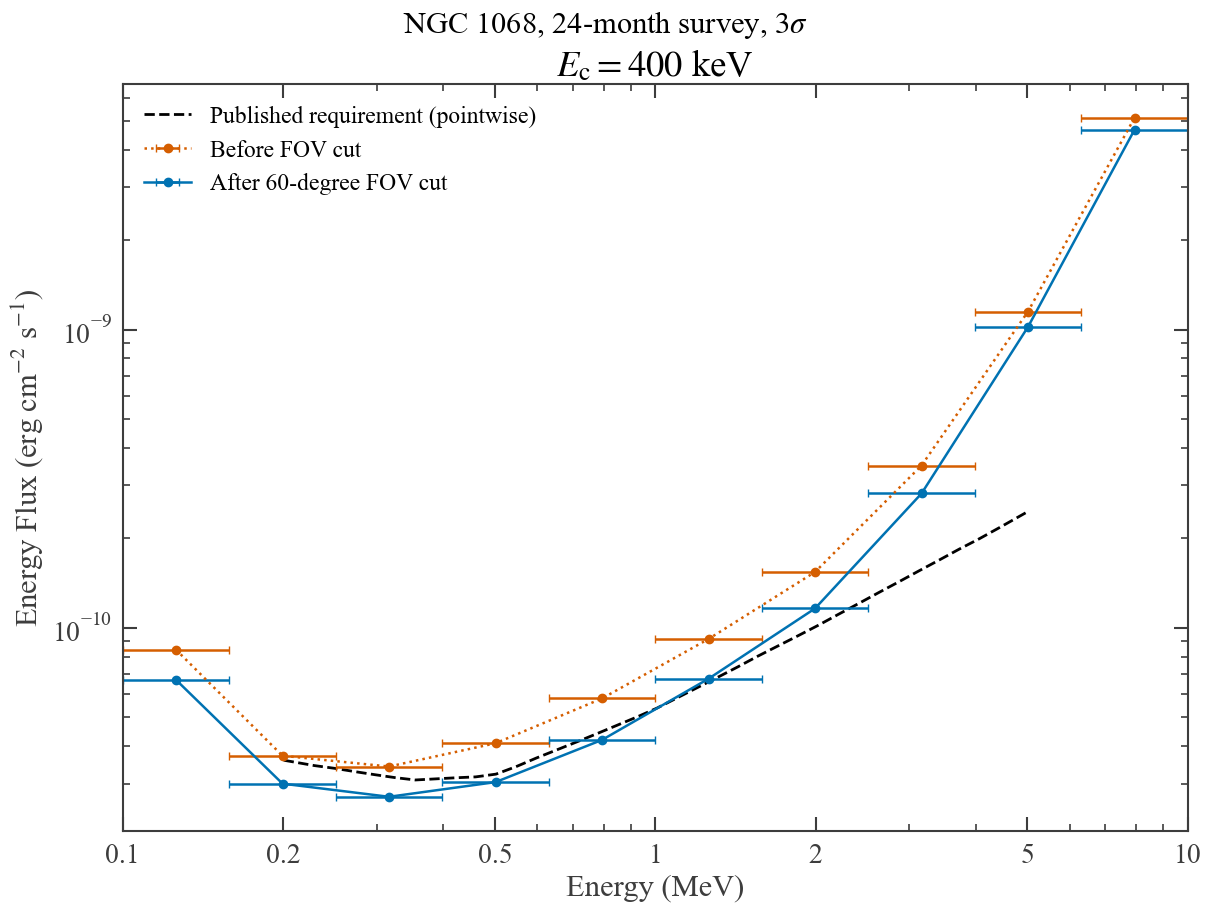

In [9]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(CUTOFFS_KEV), figsize=(12, 9),
                             sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, cutoff in zip(axes, CUTOFFS_KEV):
        ax.plot(published.energy_MeV, published.nufnu_erg_cm2_s,
                color='black', linestyle='--', linewidth=2,
                label='Published requirement (pointwise)')
        for selection in SELECTION_LABELS:
            subset = results.loc[(results.selection == selection) &
                                 (results.cutoff_keV == cutoff)].sort_values('energy_center_MeV')
            centers = subset.energy_center_MeV.to_numpy()
            xerr = np.vstack([centers - subset.energy_min_keV.to_numpy()/1000,
                              subset.energy_max_keV.to_numpy()/1000 - centers])
            ax.errorbar(centers, subset.band_mean_nufnu_erg_cm2_s, xerr=xerr,
                        color=COLORS[selection], marker='o', markersize=6,
                        linestyle='-' if selection == 'fov60' else ':',
                        linewidth=1.8, capsize=3, label=SELECTION_LABELS[selection])
        style_axes(ax)
        ax.set_yscale('log')
        ax.set_xlim(0.1, 10.0)
        ax.set_xlabel('Energy (MeV)')
        ax.set_title(rf'$E_{{\rm c}} = {cutoff:g}$ keV')
        ax.legend(loc='best', frameon=False)
    axes[0].set_ylabel(r'Energy Flux (erg cm$^{-2}$ s$^{-1}$)')
    fig.suptitle(r'NGC 1068, 24-month survey, $3\sigma$', fontsize=22)
    band_mean_pdf = OUTPUT_DIR / f'{STEM}_band_mean_comparison.pdf'
    fig.savefig(band_mean_pdf, format='pdf', bbox_inches='tight')
    plt.show()
print('Saved:', band_mean_pdf)

## 8. Effect of the FOV cut

This ratio compares two calculations using identical energy bands and source
shapes, so it is unaffected by the unpublished bandwidth convention of the
reference curve. Values below the horizontal line favor the 60-degree cut.

Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_band_sensitivity_FOV_comparison/NGC1068_24months_index_m2p1_native_bands_TS9_FOV_threshold_ratio.pdf


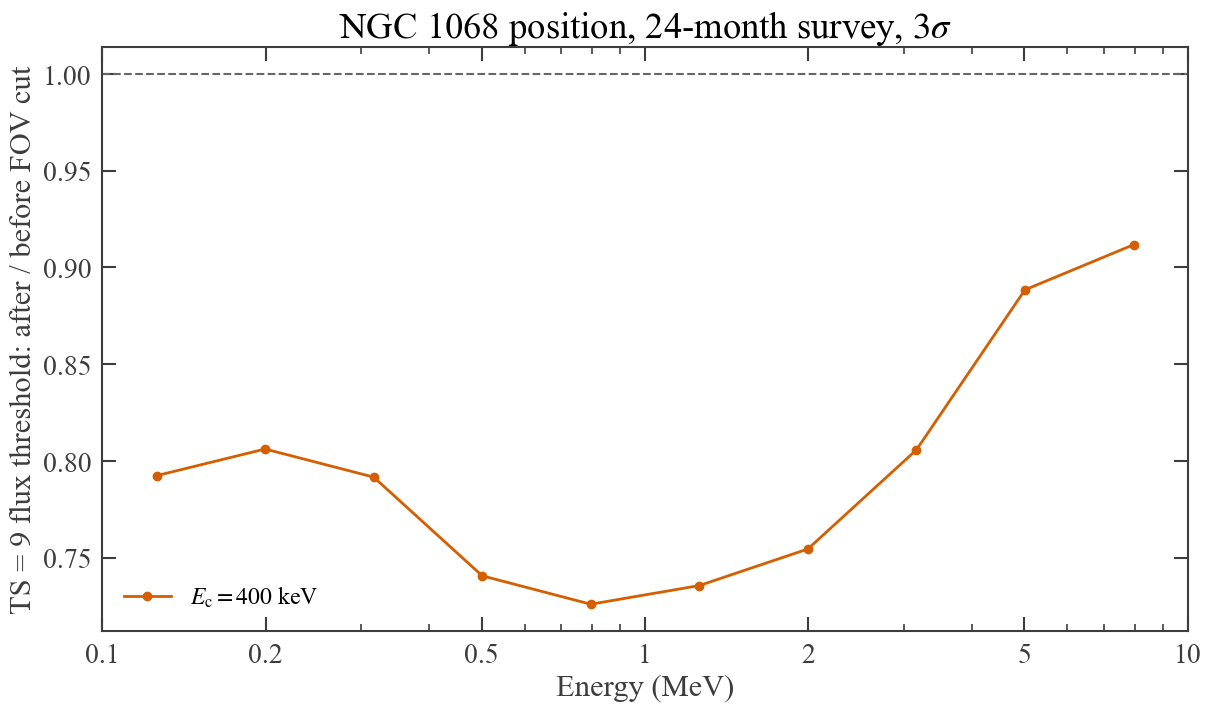

In [10]:
with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
    for cutoff in CUTOFFS_KEV:
        color = '#D55E00'
        subset = comparison.loc[comparison.cutoff_keV == cutoff].sort_values('energy_center_MeV')
        ax.plot(subset.energy_center_MeV, subset.threshold_ratio_after_over_before,
                marker='o', color=color, linewidth=2, label=rf'$E_{{\rm c}} = {cutoff:g}$ keV')
    ax.axhline(1, color='0.4', linestyle='--', linewidth=1.5)
    style_axes(ax)
    ax.set_xlim(0.1, 10.0)
    ax.set_xlabel('Energy (MeV)')
    ax.set_ylabel('TS = 9 flux threshold: after / before FOV cut')
    ax.set_title(r'NGC 1068 position, 24-month survey, $3\sigma$')
    ax.legend(frameon=False)
    ratio_pdf = OUTPUT_DIR / f'{STEM}_FOV_threshold_ratio.pdf'
    fig.savefig(ratio_pdf, format='pdf', bbox_inches='tight')
    plt.show()
print('Saved:', ratio_pdf)

## 9. Count support and energy-migration diagnostics

Zero-background cells are excluded separately in each selection, as in the
original Asimov notebook. The retained-source fraction quantifies their effect.
Source counts at the same integrated band flux of \(10^{-10}\) erg cm\(^{-2}\)
s\(^{-1}\) allow a count comparison at fixed input flux. Source counts at TS = 9
instead refer to each selection's own threshold.

The same-true-energy-band fraction measures the part of the selected source
expectation originating inside that band's true-energy boundaries. A low value
means the threshold depends strongly on migration from the assumed spectrum
outside the band. Such a result is not a model-independent differential
sensitivity. Coarse true- and measured-energy response bins remain a limitation.

In [11]:
for cutoff in CUTOFFS_KEV:
    print(f'Cutoff = {cutoff:g} keV')
    subset = diagnostics.loc[diagnostics.cutoff_keV == cutoff]
    table = pd.DataFrame({
        'Selection': subset.selection.map({'no_fov_cut': 'Before', 'fov60': 'After'}),
        'Band (keV)': [f'{lo:.1f}-{hi:.1f}' for lo, hi in zip(subset.energy_min_keV, subset.energy_max_keV)],
        'Background counts': subset.background_counts,
        'Source at F=1e-10': subset.source_counts_at_band_flux_1e_m10,
        'Source at TS=9': subset.source_counts_at_TS9,
        'Signal retained': subset.retained_source_fraction,
        'Same true band': subset.same_true_energy_band_fraction,
    })
    display(table.style.hide(axis='index').format({
        'Background counts': '{:,.0f}', 'Source at F=1e-10': '{:,.1f}',
        'Source at TS=9': '{:,.1f}', 'Signal retained': '{:.4%}', 'Same true band': '{:.2%}',
    }))
print('Interpretation: lower flux thresholds mean better sensitivity.')
print('Published comparison ratios are benchmarks; the FOV ratios compare matched native bands.')
print('Only PDFs and the two comparison CSV tables were written.')

Cutoff = 400 keV
Interpretation: lower flux thresholds mean better sensitivity.
Published comparison ratios are benchmarks; the FOV ratios compare matched native bands.
Only PDFs and the two comparison CSV tables were written.


Selection,Band (keV),Background counts,Source at F=1e-10,Source at TS=9,Signal retained,Same true band
Before,100.0-158.5,"182,371,952","158,174.3","61,420.6",100.0000%,83.85%
Before,158.5-251.2,"365,802,408","361,046.3","61,815.2",99.9993%,86.89%
Before,251.2-398.1,"282,171,912","311,341.6","49,044.2",100.0000%,89.39%
Before,398.1-631.0,"189,871,600","176,625.4","33,306.2",100.0000%,91.72%
Before,631.0-1000.0,"125,220,888","94,759.5","25,253.7",99.9998%,94.46%
Before,1000.0-1584.9,"100,587,912","50,623.5","21,356.8",100.0000%,96.71%
Before,1584.9-2511.9,"67,615,448","25,296.5","17,904.7",100.0000%,97.47%
Before,2511.9-3981.1,"28,506,368","7,838.7","12,625.5",99.9939%,97.47%
Before,3981.1-6309.6,"6,418,192","1,490.2","7,886.0",99.8691%,97.65%
Before,6309.6-10000.0,"621,672",112.5,"2,658.0",95.6248%,96.86%
